# CoDiNE

In [1]:
from railroad import *

RAILROAD_CSS = """
svg.railroad-diagram path {
  stroke-width:3;
  stroke:black;
  fill:rgba(0,0,0,0);
}
svg.railroad-diagram text {
  font:bold 14px monospace;
  font-family: "Fira Code";
  text-anchor:middle;
}
svg.railroad-diagram text.label{
  text-anchor:start;
}
svg.railroad-diagram text.comment{
  font:italic 12px monospace;
}
svg.railroad-diagram rect{
  stroke-width:3;
  stroke:black;
  fill:hsl(30,20%,95%);
}
svg.railroad-diagram rect.group-box {
  stroke: gray;
  stroke-dasharray: 10 5;
  fill: none;
}
"""

def show_diagram(d):
  result = []
  d.writeStandalone(result.append, css = RAILROAD_CSS)
  return '\n'.join(result)

Diagram._repr_svg_ = show_diagram

## Scopo del progetto

Scopo del progetto è implementare un **interprete** o un **compilatore** per CoDiNE, un linguaggio imperativo e staticamente tipato per il supporto al **Co**ntrollo **Di**mensionale e alla **N**ormalizzazione di **E**spressioni.

In CoDiNE le variabili, i parametri formali e i valori di ritorno delle funzioni hanno un **tipo** espresso come espressione dimensionale (ad esempio `m / s`, `kg * m / s ^ 2`). Il type checker verifica staticamente la compatibilità dei tipi e inserisce automaticamente le conversioni necessarie tra tipi compatibili.

<div class="alert alert-warning">
<p>Questa è la <strong>versione @@</strong> del progetto, pubblicata per consentire una analisi preliminare da parte degli studenti.</p>
<p>Prima di iniziare lo sviluppo del progetto <em>attendete che venga pubblicata la versione definitiva</em> e di esservi <em>accordati col docente</em> sugli aspetti legati al contenuto dell'insegnamento.</p>
</div>

## Il linguaggio CoDiNE

CoDiNE è un linguaggio imperativo con un sistema di tipi basato sulle unità di misura. Le caratteristiche principali sono:

* le **dichiarazioni** di dimensioni e unità definiscono il vocabolario dimensionale del programma;
* le **variabili**, i **parametri** e i valori restituiti dalle funzioni hanno un **tipo** espresso come espressione dimensionale (`m / s`, `kg`, `Num`, …);
* il sistema del controllo dimensionale verifica la **compatibilità dei tipi**
  prima dell'esecuzione.

Un esempio di programma:

```
dimension Lunghezza with unit m
dimension Tempo     with unit s
dimension Massa     with unit kg

unit km = 1000 * m
unit h  = 3600 * s
unit N  = kg * m / s ^ 2
unit g  = 981 / 100 * m / s ^ 2

def forza_peso(m : kg) : N {
    var f = m * g
    return f
}

def main(massa : kg, altezza : m) : N * m {
    var f = forza_peso(massa)
    var e = f * altezza
    return e
}
```

### Sintassi

Questa sezione presenta formalmente la sintassi del linguaggio facendo uso dei
[diagrammi sintattici](https://en.wikipedia.org/wiki/Syntax_diagram) per non
influenzare la progettazione della grammatica formale.

Un'**espressione** è formata da identificatori, letterali interi, `Num`, operatori binari e chiamate di funzione:

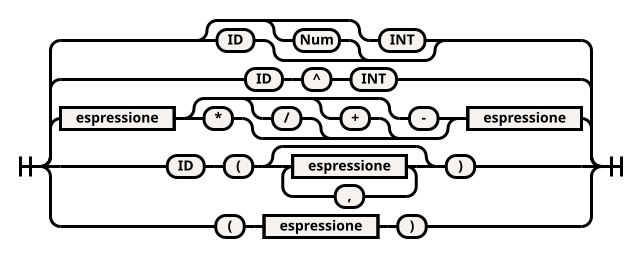

In [2]:
E = NonTerminal('espressione')
call = Sequence('ID', '(', ZeroOrMore(E, ','), ')')
Diagram(Choice(3,
    HorizontalChoice('ID','Num', 'INT'),
    Sequence('ID', '^', 'INT'),
    Sequence(E, HorizontalChoice('*', '/', '+', '-'), E),
    call,
    Sequence('(', E, ')'),
))

Una **condizione** è formata da operatori di confronto e operatori logici:

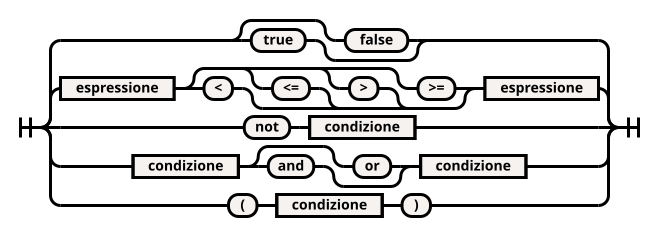

In [3]:
C = NonTerminal('condizione')
E = NonTerminal('espressione')
Diagram(Choice(2,
    HorizontalChoice('true', 'false'),
    Sequence(E, HorizontalChoice('<', '<=', '>', '>='), E),
    Sequence('not', C),
    Sequence(C, HorizontalChoice('and', 'or'), C),
    Sequence('(', C, ')'),
))

Una **dichiarazione** è:

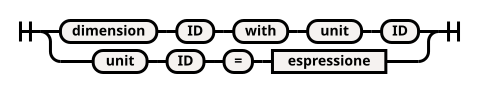

In [4]:
dim_decl  = Sequence('dimension', 'ID', 'with', 'unit', 'ID')
unit_decl = Sequence('unit', 'ID', '=', NonTerminal('espressione'))
Diagram(Choice(0, dim_decl, unit_decl))

Una **definizione di funzione** è composta da un'intestazione e un **corpo**:

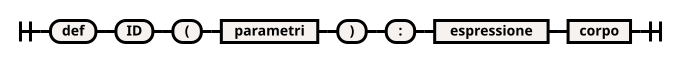

In [5]:
Diagram(Sequence('def', 'ID', '(', NonTerminal('parametri'), ')', ':', NonTerminal('espressione'), NonTerminal('corpo')))

dove i **parametri** formali sono:


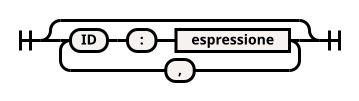

In [6]:
Diagram(ZeroOrMore(Sequence('ID', ':', NonTerminal('espressione')), ','))

dove il **corpo** è costituito da una parte di dichiarazioni di variabile e da
una parte di istruzioni:

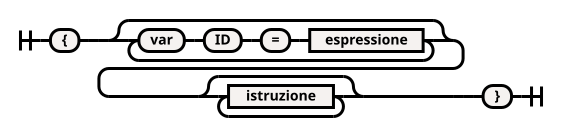

In [7]:
var_decl = Sequence('var', 'ID', '=', NonTerminal('espressione'))
Diagram(Sequence('{', Stack(ZeroOrMore(var_decl), ZeroOrMore(NonTerminal('istruzione'))), '}'))

Un'**istruzione** può essere:

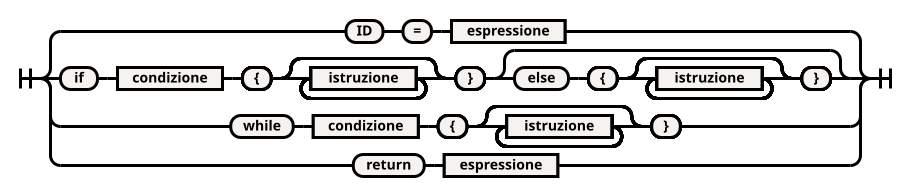

In [8]:
C = NonTerminal('condizione')
E = NonTerminal('espressione')
corpo       = Sequence('{', ZeroOrMore(NonTerminal('istruzione')), '}')
assign_stmt = Sequence('ID', '=', E)
if_stmt     = Sequence('if', C, corpo, Optional(Sequence('else', corpo)))
while_stmt  = Sequence('while', C, corpo)
return_stmt = Sequence('return', E)
Diagram(Choice(1, assign_stmt, if_stmt, while_stmt, return_stmt))

Un **programma** è una sequenza non vuota di dichiarazioni e definizioni di funzioni:

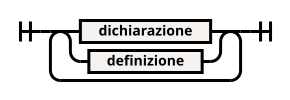

In [9]:
Diagram(OneOrMore(Choice(0, NonTerminal('dichiarazione'), NonTerminal('definizione'))))

Le **parole riservate** sono: `dimension`, `unit`, `with`, `def`, `var`, `return`, `if`, `else`, `while`, `Num`, `true`, `false`, `and`, `or`, `not`.

Un **ID** è un *identificatore* composto da una sequenza di lettere, cifre e
underscore che inizia con una lettera o un underscore e non comprende le parole
riservate; un **INT** è una *letterale intero* composto da una sequenza di cifre
decimali (senza segno e zeri a sinistra) eventualmente preceduto dal segno '-'.

#### Precedenza e associatività

La precedenza e associatività degli operatori che figurano nell'`espressione` in
ordine di precedenza dalla più bassa alla più alta:

* `+` e `-`, associativi a sinistra;
* `*` e `/`, associativi a sinistra;
* `^`;
* chiamate di funzione `f(…)`;
* parentesi `(` e `)`.

La precedenza e associatività degli operatori che figurano nella `condizione` in
ordine di precedenza dalla più bassa alla più alta:

* `or`, associativo a sinistra;
* `and`, associativo a sinistra;
* `not`, prefisso;
* confronti (`<`, `<=`, `>`, `>=`), non associativi;
* parentesi `(` e `)`.

### Espressioni e condizioni

#### Le categorie di identificatori

Gli identificatori esercitano ruoli diversi a seconda del contesto in cui
compaiono:

* le dichiarazioni `dimension` e `unit` introducono nuovi identificatori che
  rappresentano rispettivamente *dimensioni* fondamentali e *unità* di misura
  (rispettivamente *base* o *derivate*);
* le dichiarazioni `def` introducono nuovi identificatori che rappresentano
  *nomi di funzione*;
* i **parametri formali** e le **variabili** (dichiarate con `var`) sono
  **identificatori di valore**, locali alla funzione.

#### Le categorie di espressioni

Sebbene dal punto di vista sintattico esista un solo non terminale `espressione`
che rappresenta tutte le possibili espressioni del linguaggio, dal punto di
vista semantico è utile considerare tre specifiche sottoclassi di
**espressioni** a seconda degli operatori che vi compaiono:

- la classe $\mathbb{D}$ delle **espressioni dimensionali** che contengono solo
  identificatori corrispondenti a unità, operatori moltiplicativi `*`, `/`, `^`
  e parentesi (queste espressioni non contengono letterali interi se non a
  destra dell'operatore `^`); un'espressione di questa classe è anche detta un
  **tipo**;

- la classe $\mathbb{U}$ delle **espressioni di unità** che sono espressioni
  dimensionali in cui possono eventualmente comparire anche i letterali interi;

- la classe $\mathbb{V}$ delle **espressioni di valore** che sono espressioni
  (quindi con tutti i possibili operatori e chiamate di funzione) in cui deve
  comparire almeno un letterale intero (non a destra dell'operatore `^`), un
  identificatore di valore, o una chiamata di funzione.

Questa distinzione si riflette imponendo delle restrizioni semantiche sul
contesto in cui il non terminale `espressione` può comparire:

* a destra del segno `:` (nelle definizioni di funzione, per i parametri e il
  tipo di ritorno) devono essere *tipi*;
* a destra del segno `=` in una dichiarazione di `unit` devono essere
  *espressioni di unità*;
* a destra del segno `=` in una dichiarazione `var`, un assegnamento o dopo il
  `return` devono essere *espressioni di valore*.

##### Relazioni tra classi

Si osservi che i tipi e le espressioni di unità sono chiusi rispetto agli
operatori moltiplicativi, e che un'espressione di valore (a meno di errori di
tipo, descritti più avanti) può sempre essere condotta in forma canonica come
espressione di unità.

Vale inoltre che:

* $\mathbb{D} \subsetneq \mathbb{U}$: ogni espressione dimensionale è anche una
  espressione di unità se si aggiungono gli interi, ma non viceversa: ad esempio
  `3 * m / s` è un'espressione di unità ma non è un'espressione dimensionale;
* $\mathbb{U} \cap \mathbb{V} \neq \emptyset$: ad esempio `3 * m / s` appartiene
  sia a $\mathbb{U}$ sia a $\mathbb{V}$;
* $\mathbb{D} \cap \mathbb{V} = \emptyset$: una pura espressione dimensionale
  (senza interi) non è una espressione di valore.


#### Il valore di una espressione

Date $k$ dichiarazioni di dimensioni fondamentali lo **spazio delle dimensioni**
è lo spazio vettoriale $\mathbb{Z}^k$ (dove $\mathbb{Z}$ è l'insieme degli
interi), in cui l'$i$-esima dimensione fondamentale relativa all'unità $u_i$ è
rappresentata dal vettore $\mathbf{e}_i$ avente un 1 nella posizione $i$-esima
(e 0 nelle altre). Dato un vettore dimensionale $\mathbf{v}\in \mathbb{Z}^k$ il
suo **tipo canonico** è $\tau(\mathbf{v}) = u_1^{v_1} \cdot \cdots \cdot u_k^{v_k}$.

Secondo l'esempio precedente, date le dimensioni di lunghezza, tempo e massa,
alle unità di base corrispondono i vettori:

| $i$ | $u_i$ | $\mathbf{e}_i$ |
|---|---|---|
| 1 | `m`  | $(1,0,0)$ |
| 2 | `s`  | $(0,1,0)$ |
| 3 | `kg` | $(0,0,1)$ |

e al vettore dimensionale $(1,-2,1)$ corrisponde il tipo canonico $\text{kg}
\cdot \text{s} ^ {-2} \cdot \text{m} = \text{kg} \cdot \text{m} / \text{s} ^
{2}$.

A ciascuna espressione di unità $u\in \mathbb{U}$ è possibile associare il
**valore** dato dalla coppia

$$
\left(\mathfrak{D}(u), \mathfrak{N}(u)\right)\in \mathbb{Z}^k \times \mathbb{Q}
$$

dove $\mathfrak{D}$ e $\mathfrak{N}$ sono le funzioni 

$$ 
\begin{aligned}
\mathfrak{D} &: \mathbb{U} \to \mathbb{Z}^k \\
\mathfrak{N} &: \mathbb{U} \to \mathbb{Q}
\end{aligned}
$$ 

(dove $\mathbb{Q}$ è il campo dei numeri razionali) definite per induzione
strutturale:

| Espressione | $\mathfrak{D}$ | $\mathfrak{N}$ |
|---|---|---|
| unità base $u$ dell'$i$-esima dimensione | $\mathbf{e}_i$ | $1$ |
| unità derivata $u$ (da `unit u = e`) | $\mathfrak{D}(e)$ | $\mathfrak{N}(e)$ |
| `Num` | $\mathbf{0}$ | $1$ |
| $k$ (intero) | $\mathbf{0}$ | $k$ |
| $e\cdot f$ | $\mathfrak{D}(e) + \mathfrak{D}(f)$ | $\mathfrak{N}(e) \cdot \mathfrak{N}(f)$ |
| $e / f$ | $\mathfrak{D}(e) - \mathfrak{D}(f)$ | $\mathfrak{N}(e) / \mathfrak{N}(f)$ |
| $u^k$ ($u$ unità) | $k \cdot \mathfrak{D}(u)$ | $\mathfrak{N}(u)^k$ |

Si osservi che `Num` così definita risulta essere un'unità di base
*adimensionale*: i letterali interi hanno tipo `Num` (il che permette di usare
variabili adimensionali come contatori o indici).

Secondo le definizioni dell'esempio precedente

| Espressione | $\mathfrak{D}$ | $\mathfrak{N}$ |
|---|---|---|
| `3` | $\mathbf{0}$ | $3$ |
| `km` | $(1,0,0)$ | $1000$ |
| `h` | $(0,1,0)$ | $3600$ |
| `N` | $(1,-2,1)$ | $1$ |
| `g` | $(1,-2,0)$ | $\tfrac{981}{100}$ |
| `km / h` | $(1,-1,0)$ | $\tfrac{5}{18}$ |
| `m / s` | $(1,-1,0)$ | $1$ |

Due tipi $t_1, t_2$ sono **compatibili** (in simboli $t_1 \sim t_2$) se e solo
se hanno lo stesso vettore dimensionale, cioè $\mathfrak{D}(t_1) =
\mathfrak{D}(t_2)$; la compatibilità si estende naturalmente a qualunque coppia
di espressioni di cui sia definito $\mathfrak{D}$. Se $u\in \mathbb{U}$, allora
$u \sim \tau(\mathfrak{D}(u))$ e l'espressione

$$
u = \mathfrak{N}(u) \cdot \tau(\mathfrak{D}(u))
$$

è detta la forma **canonica** di $u$.

Seguendo il solito esempio $5\; \text{m} / \text{s}$ è la forma canonica di
$18\; \text{km} / \text{h}$.

Consideriamo ora le espressioni di valore della forma $e \diamond f$, dove
$\diamond$ è una somma o sottrazione e $e, f \in \mathbb{U}$. Tali espressioni
hanno senso solo nel caso in cui $e \sim f$ per cui è naturale estendere le
funzioni $\mathfrak{D}$ e $\mathfrak{N}$ come segue:

$$
\begin{aligned}
\mathfrak{N}(e\diamond f) &= \mathfrak{N}(e) \diamond \mathfrak{N}(f) \\
\mathfrak{D}(e\diamond f) &= \mathfrak{D}(e) = \mathfrak{D}(f)
\end{aligned}
$$

il che corrisponde sostanzialmente a dire che prima di eseguire le operazioni
additive, le espressioni vengono portate in forma **canonica** in modo da essere
costituite ciascuna dal prodotto tra un razionale e il tipo comune. In mancanza
di compatibilità l'espressione costituisce un **errore di tipo**.

Ad esempio $18\; \text{km} / \text{h} + 3\; \text{m} / \text{s} = 8\; \text{m} /
\text{s}$.

##### L'esecuzione

Quanto descritto sin qui può essere determinato prima dell'esecuzione, nella
fase di *analisi statica*. Per stabilire il valore di una espressione è però in
generale necessario fare riferimento anche all'esecuzione (descritta in
dettaglio nella sezione seguente), sia per quanto concerne le variabili che le
chiamate di funzione.

Se $v$ è un identificatore di valore, allora il suo valore è quello dell'ultima
espressione di valore che gli è stata *assegnata*.

Resta ora solo il caso delle chiamate di funzione, sia $f$ una funzione con
$n\ge 0$ parametri formali $p_i$ di tipo $t_i$ e con tipo di ritorno $r$. Date
le espressioni $e_1, \ldots, e_n$, l'invocazione

$$
f(e_1, \ldots, e_n)
$$

ha senso solo qualora $e_i \sim t_i$ per ogni $i$; in tal caso si assuma che $v
\sim r$ sia l'espressione valore restituita dall'esecuzione della funzione (vedi
la sezione **Dichiarazioni, istruzioni ed esecuzione**), e che tale valore sia
ottenuto tramite l'invocazione dell'istruzione `return` qualora a ciascun
parametro $p_i$ si sia sostituita l'espressione $\mathfrak{N}(e_i) \cdot
\tau(\mathfrak{D}(e_i))$. Vale allora che:

$$
\begin{aligned}
\mathfrak{N}(f(e_1, \ldots, e_n)) &= \mathfrak{N}(v) \\
\mathfrak{D}(f(e_1, \ldots, e_n)) &= \mathfrak{D}(r)
\end{aligned}
$$

Qualora manchi una qualunque delle compatibilità sopra descritte, l'invocazione
costituisce un **errore di tipo**.

#### Il valore di una condizione

Il valore di una condizione è un "vero" o "falso" e si ottiene valutando le
espressioni di valore che vi compaiono, quindi:

* applicando gli operatori di confronto solo tra espressioni compatibili e
  confrontando i loro valori razionali ottenuti con $\mathfrak{N}$;
* valutando gli operatori logici `and`, `or`, `not` e i letterali `true` e `false`
  secondo l'usuale semantica.

### Dichiarazioni, istruzioni ed esecuzione

#### Visibilità degli identificatori

Gli identificatori che rappresentano unità e nomi di funzione sono **globali**,
non possono essere ridefiniti e le definizioni di unità non possono contenere
cicli (mentre quelle di funzione sì, per consentire la ricorsione).

I **parametri formali** e le **variabili** sono **identificatori di valore**
locali alla funzione; le variabili sono dichiarate nel preambolo del corpo della
funzione, prima di qualsiasi istruzione.

#### Dichiarazioni di variabili

`var x = v` dichiara la variabile $x$ inizializzandola all'espressione di valore
$v$; il suo tipo è inferito come $\tau(\mathfrak{D}(v))$ e non può variare nelle
assegnazioni successive.

#### Istruzioni

Le istruzioni hanno l'usuale semantica, fermo restando che i tipi devono essere
compatibili:

* `x = v` assegna alla variabile $x$ l'espressione di valore $v$ se $v \sim d$
  dove $d$ è il tipo di $x$;
* `return v` restituisce il valore $v$ se $v \sim r$ dove $r$ è il tipo di
  ritorno dichiarato della funzione;
* `if` esegue le istruzioni tra le graffe dopo la condizione se è vera,
  altrimenti esegue le istruzioni tra le graffe dopo l'`else`;
* `while` esegue le istruzioni tra graffe finché la condizione è vera.

Laddove una qualunque delle compatibilità sopra descritte non sia soddisfatta,
l'istruzione costituisce un **errore di tipo**.

#### Controllo del return

L'analizzatore semantico deve verificare staticamente che ogni funzione
**termini sempre tramite un'istruzione `return`**, indipendentemente dal
percorso di esecuzione seguito. Questo controllo, noto come
[*definite return*](https://en.wikipedia.org/wiki/Definite_assignment_analysis),
si effettua per induzione sulla struttura sintattica delle istruzioni,
definendo quando un'istruzione (o una sequenza di istruzioni) **garantisce** di
terminare con un `return`:

| Istruzione | Condizione garantita |
|---|---|
| `return E` | sì |
| `if C { S1 } else { S2 }` | sì se e solo se sia `S1` sia `S2` lo garantiscono |
| `if C { S1 }` (senza `else`) | no |
| `while C { S }` | no |
| assegnamento `x = E` | no |
| sequenza `S1 … Sn` | sì se e solo se almeno uno degli `Si` lo garantisce |

Il corpo di una funzione supera il controllo se e solo se la sua sequenza di
istruzioni garantisce il ritorno. L'analisi è conservativa: esistono funzioni
che in pratica terminano sempre con `return` ma che non superano il controllo
(ad esempio un `while true { return … }`); tuttavia, se il controllo ha esito
positivo si ha la garanzia che ogni esecuzione che termina lo fa tramite
`return`.

#### Esecuzione del programma

La funzione `main` è il punto di ingresso del programma. L'interprete o il
compilatore riceve in ingresso tante frazioni $q_1, \ldots, q_n$ quanti sono i
parametri formali di `main`; ciascuna frazione $q_i$ è intesa come il
coefficiente nella unità dichiarata per il parametro $p_i$ di tipo $t_i$:
l'argomento passato al parametro $p_i$ è $q_i \cdot t_i$.

Il risultato prodotto da `main` viene restituito come la frazione che compare
nella forma canonica dell'espressione di valore restituita, ossia
$\mathfrak{N}(v)$ dove $v$ è l'espressione valore restituita dal `return` che ha
terminato l'esecuzione.

Ad esempio, con il programma precedente, se `main` riceve `2` e `3` (ossia
`massa = 2 kg` e `altezza = 3 m`), calcola l'energia $2 \cdot \tfrac{981}{100}
\cdot 3 = \tfrac{5886}{100} = \tfrac{2943}{50}$ e l'output del programma è
$2943/50$.

## Dettagli progettuali e implementativi

Obiettivo del progetto è scrivere un **interprete** o un **compilatore** per CoDiNE.

Per svolgere il progetto sarà necessario:

1. Specificare una **grammatica** per CoDiNE che determini quali programmi sono
   sintatticamente validi, tenendo conto della precedenza degli operatori e
   rendendo praticabile la ricostruzione della struttura astratta del programma.

2. Implementare un **parser** in grado di ricostruire tale struttura a partire
   dal testo sorgente.

3. Implementare un **analizzatore semantico** che:
   * elabori le dichiarazioni di dimensioni e unità, costruendo il
     modello dimensionale;
   * verifichi staticamente la compatibilità dei tipi di ogni espressione,
     istruzione e chiamata di funzione;
   * verifichi la presenza di una funzione `main` e che ciascun ramo di
     esecuzione di ogni funzione termini con un'istruzione `return`.

4. Implementare l'**esecutore**: un interprete che valuta le espressioni e le
   istruzioni, oppure un compilatore che traduce il programma in un linguaggio
   target (bytecode, Python, LLVM IR, …) dopo l'analisi semantica; i numeri
   razionali non devono essere rappresentati come numeri in virgola mobile, ma
   devono essere rappresentati in modo esatto (ad esempio come coppie di interi)
   e le operazioni su di essi devono essere implementate in modo da restituire
   sempre risultati ridotti ai minimi termini.

L'interprete può incontrare a run-time errori non rilevabili staticamente (ad
esempio divisione per zero); è possibile scegliere come gestirli, da un semplice
messaggio d'arresto a una segnalazione dettagliata.

### Organizzazione del codice, documentazione e testing

Al fine di formulare la sua valutazione, il docente deve non solo accertare il
corretto funzionamento dell'interprete o compilatore, ma essere in grado di
comprendere il codice che lo realizza, con particolare riferimento alle scelte
progettuali, le strutture dati e la sua organizzazione.

Sebbene non sia richiesta una documentazione formale, si suggerisce di
realizzare il codice in modo modularizzato, provvedendo un minimo di commenti
che ne chiariscano la struttura e il comportamento, in particolare nelle parti
in cui è stata effettuata una scelta progettuale o adottata una soluzione non
ovvia.

Il codice deve essere strutturato in modo tale che sia possibile eseguire
diversi programmi CoDiNE raccogliendone l'output in modo semplice. La
valutazione sarà basata (tra l'altro) su una batteria di test di integrazione
messa a disposizione degli studenti assieme a questo testo.

### Test di integrazione

Per verificare la correttezza dell'implementazione viene fornito un supporto
alla realizzazione di test di integrazione attraverso una batteria di sorgenti
accompagnati da input di prova e output attesi. 

Tale materiale è contenuto nella directory `tests/` che ha la seguente struttura:

```
tests/
  <nome>/
    sorgente.codine
    input-N.txt
    expected-N.txt
```

dove `<nome>` è un nome descrittivo del test (ad esempio `fact` per il test
della fattoriale) e `N` è soistituito da un numero progressivo che identifica i
diversi casi di test per lo stesso sorgente.

I test coprono le seguenti situazioni:

| Directory | Aspetto verificato |
|---|---|
| `fact/` | ricorsione su `Num` |
| `fib/` | ricorsione su `Num` |
| `sumN/` | ciclo `while` su `Num` |
| `maxval/` | istruzione `if`/`else` con tipi dimensionali |
| `energy/` | dichiarazioni di dimensioni e unità, chiamate di funzione (esempio del testo) |
| `arith/` | operazioni aritmetiche, frazioni esatte |
| `unitconv/` | conversione automatica di unità nella somma |
| `pythagorean/` | operatore `^`, tipo di ritorno `m^2` |
| `rationals/` | aritmetica razionale esatta |
| `velocity/` | output con valore frazionario e tipo dimensionale |

#### Formato di input e output

**Input** (`input-N.txt`): un valore per riga nella forma `P/Q` (o intero `N`), nell'ordine dei parametri di `main`. Se `main` non ha parametri, il file è vuoto.

**Output** (`expected-N.txt`): una singola riga contenente la frazione $\mathfrak{N}(v)$ restituita dal `return` finale, nella forma `P/Q` ridotta ai minimi termini (o intero `N` se il denominatore è 1).

**Esempio** — il programma `energy/sorgente.codine` calcola l'energia potenziale; con `input-1.txt`:
```
2
3
```
l'output atteso in `expected-1.txt` è:
```
2943/50
```
ossia $2\,\text{kg} \times \tfrac{981}{100}\,\text{m/s}^2 \times 3\,\text{m} = \tfrac{2943}{50}\,\text{J}$.

#### Come usare i test

Come richiesto, l'implementazione deve esporre un'interfaccia (ad esempio a riga
di comando) che renda possibile eseguire un programma e raccoglierne l'output.
Supponendo che l'implementazione sia realizzata in Python e che il modulo
principale sia `main.py`, tale interfaccia deve:

1. riceva il percorso del sorgente CoDiNE come argomento;
2. legga da *stdin* i valori dei parametri di `main` (uno per riga);
3. stampi su *stdout* il risultato nella forma `P/Q`.

Una volta realizzata tale interfaccia è possibile eseguire un singolo test con:

```
python -m <modulo> tests/fact/sorgente.codine < tests/fact/input-5.txt
```

e confrontare l'output con `tests/fact/expected-5.txt`.